In [ ]:
# ================================================================
# PTP + Agarwal-style Synthetic Dataset (Spikes + LFP)
# with Allowed Track Segments and Place-Modulated LFP Phase Jitter
# ================================================================

import numpy as np, matplotlib.pyplot as plt, os, pickle
from scipy.signal import butter, filtfilt, hilbert
from scipy.ndimage import gaussian_filter1d
from sklearn.decomposition import PCA
from scipy.stats import circmean
# ============================
from scipy.signal import sawtooth

In [ ]:

# -----------------------------
# Configuration (edit here)
# -----------------------------
SEED = 7
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# --- Timeline
fs      = 250            # Hz
T_sec   = 10            # seconds
t       = np.arange(0, T_sec, 1/fs)
N       = t.size
MODE = "biased_rw"  # "constant" | "nonstationary" | "biased_rw"

# --- Population composition (place : multi-peak : noisy : head-direction)
n_cells_total = 60
frac_place, frac_multi, frac_noisy, frac_hd = 0.3, 0.15, 0.4, 0.15
n_place      = int(n_cells_total * frac_place)
n_multipeak  = int(n_cells_total * frac_multi)
n_noisy      = int(n_cells_total * frac_noisy)
n_hd         = n_cells_total - n_place - n_multipeak - n_noisy

# --- LFP channel count
n_lfp = 8

# --- Track coverage segments
ALLOW_SEGMENTS = [(-1.0, -0.55), (-0.15, 0.15), (0.45, 0.85)]
# ALLOW_SEGMENTS = None

# --- Global theta parameters
THETA_F0 = 8.0
THETA_WOBBLE1_HZ  = 0.02
THETA_WOBBLE2_HZ  = 0.006
THETA_WOBBLE1_AMP = 0.4
THETA_WOBBLE2_AMP = 0.2

# --- Amplitude envelope
AMP_BASE         = 0.60
AMP_SPEED_GAIN   = 0.35
AMP_DRIFT_GAIN   = 0.15
AMP_DRIFT_FREQ   = 0.015

# --- LFP phase spatial modulation
CH_PHASE_JITTER_DEG = 30.0
PHASE_WIGGLE_POS1   = 0.15
PHASE_WIGGLE_POS2   = 0.08
PHASE_POS_GAIN = 0.15
AMP_POS_GAIN = 0.0

# --- PSP (spike → LFP)
PSP_KERNEL_MS  = 40
PSP_GAIN       = 0.15

# --- Noise
NOISE_WHITE_STD = 0.30
NOISE_PINK_STD  = 0.25

# --- Place field defaults
PF_WIDTH_RANGE = (0.10, 0.22)
PF_PEAK_HZ     = (6.0, 12.0)
PF_BASE_HZ     = (0.1, 0.4)
PF_KAPPA       = (2.0, 6.0)

# --- Multi-peak defaults
MP_NUM_RANGE   = (2, 4)
MP_WIDTH_RANGE = (0.12, 0.28)
MP_AMP_RANGE   = (3.0, 7.0)
MP_KAPPA       = (1.0, 3.0)

# --- Noisy units
NOISY_KAPPA    = (0.0, 1.0)
NOISY_RW_STD   = 0.04

# --- Coverage plotting
COVERAGE_N_BINS = 50


# -----------------------------
# Helpers
# -----------------------------
def allowed_mask(pos, segments):
    if segments is None:
        return np.ones_like(pos, dtype=float)
    m = np.zeros_like(pos, dtype=float)
    for a,b in segments:
        m += ((pos>=a) & (pos<=b)).astype(float)
    return np.clip(m, 0, 1)

def sample_center_from_allowed(rng, segments):
    if segments is None:
        return rng.uniform(-0.9, 0.9)
    seg = segments[rng.integers(len(segments))]
    return rng.uniform(seg[0], seg[1])

# ============================
# Movement models (pick one)


def _normalize_speed(v):
    v_abs = np.abs(v)
    return v_abs / (v_abs.max() + 1e-9)

# 1) Linear back-and-forth at constant speed (triangle wave on [-1,1])
def movement_constant_linear(t, fs, f_traversal=0.10):
    """
    f_traversal: traversals per second (0.10 => one full back+forth every 10 s)
    """
    # triangle wave in [-1, 1]
    x = sawtooth(2*np.pi*f_traversal*t, width=0.5)  # symmetric up/down
    v_animal = np.gradient(x) * fs                  # signed velocity
    v_norm = _normalize_speed(v_animal)
    return x.astype(np.float32), v_animal.astype(np.float32), v_norm.astype(np.float32)

# 2) Nonstationary speed (your current style: slow accel/decel over time)
def movement_nonstationary(t, fs,
                           base=0.22,
                           a1=0.07, f1=0.010, phi1=0.7,
                           a2=0.03, f2=0.045, phi2=1.1,
                           min_speed=0.05):
    """
    base + slow sinusoidal modulations (always >= min_speed)
    """
    speed_profile = (base
                     + a1*np.sin(2*np.pi*f1*t + phi1)
                     + a2*np.sin(2*np.pi*f2*t + phi2))
    speed_profile = np.clip(speed_profile, min_speed, None)

    # integrate speed to distance (phase), then wrap onto [-1,1] via sine
    phase = 2*np.pi * np.cumsum(speed_profile) / fs
    x = np.sin(phase)
    v_animal = np.gradient(x) * fs
    v_norm = _normalize_speed(v_animal)
    return x.astype(np.float32), v_animal.astype(np.float32), v_norm.astype(np.float32)
import numpy as np
from scipy.ndimage import gaussian_filter1d

def movement_discrete(t, fs,
                                         step_size=0.006,      # per-sample displacement → faster movement
                                         decision_interval=15, # samples between decisions (~60 ms @ 250Hz)
                                         turn_prob_scale=5.5,  # steepness of turning near wall
                                         pause_prob_base=0.05, # baseline pause chance
                                         boundary=1.0):
    """
    3-action (forward / backward / pause) movement model with soft boundaries.
    Near the boundary, animal has 50% chance to pause and 50% to turn.
    Between boundaries, it tends to continue moving, sometimes pausing.
    """

    N = len(t)
    x = np.zeros(N, dtype=np.float32)
    v = np.zeros(N, dtype=np.float32)

    direction = 1.0  # initial direction (+1 forward, -1 backward, 0 pause)

    for n in range(1, N):

        # ─ Decision rule every few samples ─
        if n % decision_interval == 0:
            # distance to nearest boundary, normalized [0,1]
            d = min((boundary - x[n-1]) / boundary,
                    (boundary + x[n-1]) / boundary)

            # --- Probabilities ---
            # General: turn probability grows near wall
            p_turn = np.exp(-turn_prob_scale * d)
            p_turn = np.clip(p_turn, 0, 1)

            # Pause probability: baseline + slightly higher near wall
            p_pause = pause_prob_base + 0.1 * (1 - d)
            p_pause = np.clip(p_pause, 0, 0.3)

            # Default forward prob = remaining
            p_forward = 1.0 - (p_turn + p_pause)
            p_forward = np.clip(p_forward, 0, 1)

            # --- Special case: at the border ---
            if abs(x[n-1]) >= 0.99 * boundary:
                p_turn = 0.5
                p_pause = 0.5
                p_forward = 0.0

            # Normalize and choose
            probs = np.array([p_forward, p_turn, p_pause])
            probs /= probs.sum()
            action = np.random.choice(["forward", "turn", "pause"], p=probs)

            if action == "turn":
                direction = -direction if direction != 0 else np.random.choice([-1, 1])
            elif action == "pause":
                direction = 0.0
            else:  # forward
                if direction == 0:
                    direction = np.random.choice([-1.0, 1.0])

        # ─ Update position ─
        x[n] = x[n-1] + direction * step_size

        # Hard reflect if we go beyond limits
        if x[n] > boundary:
            x[n] = boundary
            direction = -1.0
        elif x[n] < -boundary:
            x[n] = -boundary
            direction = 1.0

        v[n] = direction * step_size * fs

    # Smooth trajectory for continuity
    x_smooth = gaussian_filter1d(x, sigma=1.0)
    v_animal = np.gradient(x_smooth) * fs
    v_norm = np.abs(v_animal) / (np.max(np.abs(v_animal)) + 1e-9)

    return x_smooth.astype(np.float32), v_animal.astype(np.float32), v_norm.astype(np.float32)

# -----------------------------
# 1) Generate latent trajectory & global theta
# -----------------------------



if MODE == "constant":
    pos_animal, v_animal, v_norm = movement_constant_linear(t, fs, f_traversal=0.10)
elif MODE == "nonstationary":
    pos_animal, v_animal, v_norm = movement_nonstationary(t, fs)  # tweak params as desired
elif MODE == "biased_rw":
    pos_animal, v_animal, v_norm = movement_discrete(t, fs)
else:
    raise ValueError("MODE must be one of: constant, nonstationary, biased_rw")

# Keep your mask code the same:
M_allow = allowed_mask(pos_animal, ALLOW_SEGMENTS)

# Short aliases used later
x = pos_animal
M_allow = allowed_mask(x, ALLOW_SEGMENTS)

# Global theta phase
f_theta = (THETA_F0
           + THETA_WOBBLE1_AMP*np.sin(2*np.pi*THETA_WOBBLE1_HZ*t)
           + THETA_WOBBLE2_AMP*np.sin(2*np.pi*THETA_WOBBLE2_HZ*t + 0.9))
phi_theta = 2*np.pi*np.cumsum(f_theta)/fs

# Nonstationary amplitude envelope
A_env = (AMP_BASE
         + AMP_SPEED_GAIN*v_norm
         + AMP_DRIFT_GAIN*np.sin(2*np.pi*AMP_DRIFT_FREQ*t + 0.3))
A_env = np.clip(A_env, 0.1, 1.5)


# -----------------------------
# 2) Generate spiking population (place, multi, noisy, HD)
# -----------------------------
rates  = np.zeros((n_cells_total, N), dtype=np.float32)
labels = []

# --- Place cells
for i in range(n_place):
    mu  = sample_center_from_allowed(rng, ALLOW_SEGMENTS)
    sig = rng.uniform(*PF_WIDTH_RANGE)
    pk  = rng.uniform(*PF_PEAK_HZ)
    b   = rng.uniform(*PF_BASE_HZ)
    kap = rng.uniform(*PF_KAPPA)
    field = np.exp(-0.5*((x - mu)/sig)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    phase_pref = (np.pi/2) - np.pi*((x - mu)/sig)
    phase_gain = np.exp(kap * np.cos(phi_theta - phase_pref))
    rates[i]   = (b + pk * field) * phase_gain
    labels.append("place")

# --- Multi-peak cells
off = n_place
for i in range(off, off + n_multipeak):
    n_bumps = rng.integers(*MP_NUM_RANGE)
    mus  = [sample_center_from_allowed(rng, ALLOW_SEGMENTS) for _ in range(n_bumps)]
    sigs = rng.uniform(*MP_WIDTH_RANGE, size=n_bumps)
    amps = rng.uniform(*MP_AMP_RANGE, size=n_bumps)
    field = np.zeros(N)
    for m,s,a in zip(mus,sigs,amps):
        field += a*np.exp(-0.5*((x - m)/s)**2) * (M_allow if ALLOW_SEGMENTS else 1.0)
    kap  = rng.uniform(*MP_KAPPA)
    pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (rng.uniform(0.05,0.3) + field) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("multi-peak")

# --- Noisy cells
off2 = off + n_multipeak
for i in range(off2, off2 + n_noisy):
    rw = np.cumsum(rng.normal(0, NOISY_RW_STD, size=N)).astype(np.float32)
    rw = (rw - rw.min()) / (rw.max() - rw.min() + 1e-9)
    base = rng.uniform(0.2, 1.0)
    amp  = rng.uniform(2.0, 5.0)
    kap  = rng.uniform(*NOISY_KAPPA)
    pref = rng.uniform(-np.pi, np.pi)
    rates[i] = (base + amp*rw) * np.exp(kap * np.cos(phi_theta - pref))
    labels.append("noisy")

# --- Head-direction cells
off3 = off2 + n_noisy
dir_signal = np.sign(v_animal)
dir_signal[dir_signal == 0] = 1
dir_angle = np.where(dir_signal > 0, np.pi/2, -np.pi/2)
dir_angle = dir_angle + rng.normal(0, 0.15, size=N)

for i in range(off3, off3 + n_hd):
    k_dir = rng.uniform(2.0, 6.0)
    pref  = rng.uniform(-np.pi, np.pi)
    base  = rng.uniform(0.2, 1.0)
    pk    = rng.uniform(8.0, 15.0)
    kap_theta = rng.uniform(1.0, 3.0)
    theta_pref = rng.uniform(-np.pi, np.pi)
    dir_term = np.exp(k_dir * np.cos(dir_angle - pref))
    dir_term /= dir_term.max() + 1e-9
    rates[i] = (base + pk * dir_term) * np.exp(kap_theta * np.cos(phi_theta - theta_pref))
    labels.append("hd")

labels = np.array(labels)
p_spike = rates / fs
spikes  = rng.random((n_cells_total, N)) < p_spike
rates_smooth = gaussian_filter1d(spikes.astype(float), sigma=2, axis=1) * fs

print(f"Counts → place={n_place}, multi={n_multipeak}, noisy={n_noisy}, hd={n_hd}, total={len(labels)}")
print("spikes shape:", spikes.shape)
print("Trajectory:", x.shape, "Velocity:", v_animal.shape)


# -----------------------------
# 3) Spatial coverage heatmap
# -----------------------------
n_bins = COVERAGE_N_BINS
edges  = np.linspace(-1, 1, n_bins+1)
cent   = 0.5*(edges[1:] + edges[:-1])
pos_bins_all = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
occ_counts = np.bincount(pos_bins_all, minlength=n_bins)
occ_time   = occ_counts / fs + 1e-9
coverage = np.zeros((n_cells_total, n_bins), dtype=float)
for i in range(n_cells_total):
    pos_bins = np.clip(np.digitize(x, edges)-1, 0, n_bins-1)
    counts = np.bincount(pos_bins[spikes[i]], minlength=n_bins)
    coverage[i] = counts / occ_time
peak_pos = cent[np.argmax(coverage, axis=1)]
order = np.argsort(peak_pos)


# -----------------------------
# 4) Generate synthetic LFP (theta + PSP + noise)
# -----------------------------
phase_jitter = np.deg2rad(CH_PHASE_JITTER_DEG)
ch_phase = rng.uniform(-phase_jitter, phase_jitter, size=n_lfp)
x_norm = (x - x.min()) / (x.max() - x.min() + 1e-9)
phase_pos_jitter = np.zeros((N, n_lfp), dtype=np.float32)
for ch in range(n_lfp):
    a1, b1 = rng.normal(0,1), rng.normal(0,1)
    a2, b2 = rng.normal(0,1), rng.normal(0,1)
    phase_pos_jitter[:, ch] = PHASE_POS_GAIN * (
        0.6*np.sin(2*np.pi*x_norm)*a1 +
        0.4*np.cos(4*np.pi*x_norm)*b1 +
        0.3*np.sin(6*np.pi*x_norm)*a2 +
        0.2*np.cos(8*np.pi*x_norm)*b2
    )
amp_pos_jitter = np.zeros((N, n_lfp), dtype=np.float32)
if AMP_POS_GAIN != 0.0:
    for ch in range(n_lfp):
        c1, d1 = rng.normal(0,1), rng.normal(0,1)
        amp_pos_jitter[:, ch] = AMP_POS_GAIN * (
            0.5*np.sin(2*np.pi*x_norm)*c1 + 0.5*np.cos(2*np.pi*x_norm)*d1
        )
wiggle = (PHASE_WIGGLE_POS1*np.sin(2*np.pi*x)[:,None]
          + PHASE_WIGGLE_POS2*np.cos(4*np.pi*x)[:,None])
lfp_theta = (A_env[:,None] * (1.0 + amp_pos_jitter)) * \
            np.sin(phi_theta[:,None] + ch_phase[None,:] + phase_pos_jitter + wiggle)

kern_len = max(3, int(PSP_KERNEL_MS * fs / 1000) | 1)
win = np.hanning(kern_len); win /= (win.sum() + 1e-9)
psp = np.zeros((N, n_lfp), dtype=np.float32)
assign = rng.integers(0, n_lfp, size=n_cells_total)
for i in range(n_cells_total):
    s = spikes[i].astype(float)
    conv = np.convolve(s, win, mode='same').astype(np.float32)
    psp[:, assign[i]] += PSP_GAIN * conv

white = rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp)).astype(np.float32)
pink  = np.cumsum(rng.normal(0, NOISE_WHITE_STD, size=(N, n_lfp)).astype(np.float32), axis=0)
pink  = (pink - pink.mean(0)) / (pink.std(0)+1e-9) * NOISE_PINK_STD
lfp_raw = (lfp_theta + psp + white + pink).astype(np.float32)
print(f"LFP synthesized with PHASE_POS_GAIN={PHASE_POS_GAIN:.2f} (AMP_POS_GAIN={AMP_POS_GAIN:.2f})")


# -----------------------------
# 5) Theta-band filter & Hilbert
# -----------------------------
def butter_band(data, lo, hi, fs, order=3):
    b, a = butter(order, [lo, hi], btype="bandpass", fs=fs)
    return filtfilt(b, a, data)

lfp_theta_band    = np.zeros_like(lfp_raw)
lfp_phase_inst    = np.zeros_like(lfp_raw)
lfp_envelope_inst = np.zeros_like(lfp_raw)
for ch in range(n_lfp):
    lfp_theta_band[:, ch] = butter_band(lfp_raw[:, ch], 6, 10, fs)
    analytic = hilbert(lfp_theta_band[:, ch])
    lfp_envelope_inst[:, ch] = np.abs(analytic)
    lfp_phase_inst[:, ch]    = np.mod(np.angle(analytic), 2*np.pi)


Counts → place=18, multi=9, noisy=24, hd=9, total=60
spikes shape: (60, 2500)
Trajectory: (2500,) Velocity: (2500,)
LFP synthesized with PHASE_POS_GAIN=0.15 (AMP_POS_GAIN=0.00)


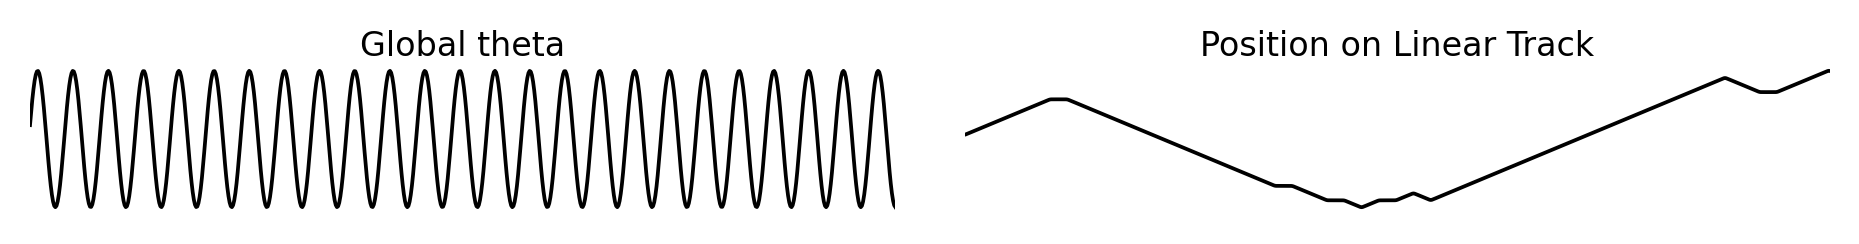

In [8]:
# --- Use only a partial window (e.g., first 3 seconds for clarity)
T_window = 3  # seconds
mask = t <= T_window
t_sub = t[mask]
phi_sub = phi_theta[mask]
x_sub = x[mask]

# --- Compute the global theta wave
theta_wave = np.sin(phi_sub)

# --- Normalize position for visual alignment
x_norm = (x_sub - np.min(x_sub)) / (np.max(x_sub) - np.min(x_sub))
x_norm = 2 * (x_norm - 0.5)

# --- Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(6, 0.5), dpi=300)

# (1) Global theta
axes[0].plot(t_sub, theta_wave, color="black", lw=0.9)
axes[0].set_xlim(t_sub[0], t_sub[-1])
axes[0].set_ylim(-1.1, 1.1)
axes[0].set_title("Global theta", fontsize=8, pad=2)
axes[0].axis("off")

# (2) Position on linear track
axes[1].plot(t_sub, x_norm, color="black", lw=0.9)
axes[1].set_xlim(t_sub[0], t_sub[-1])
axes[1].set_ylim(-1.1, 1.1)
axes[1].set_title("Position on Linear Track", fontsize=8, pad=2)
axes[1].axis("off")

plt.subplots_adjust(wspace=0.08, left=0, right=1, top=1, bottom=0)
plt.show()

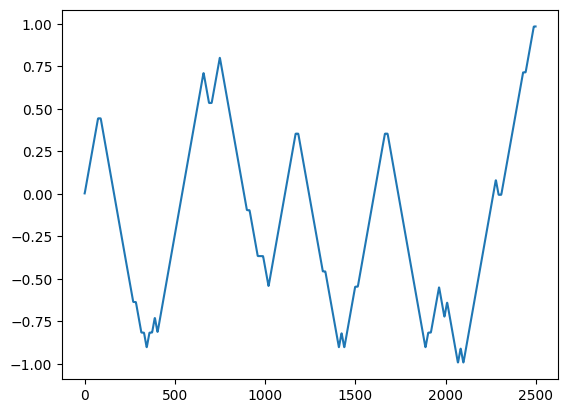

In [4]:
plt.plot(pos_animal)
# plt.plot(v_animal)
# plt.plot(speed_profile)

In [11]:
# -----------------------------
# 7) Final dataset dict & save
# -----------------------------
dataset = dict(
    # Spiking
    spikes_binary       = spikes.T.astype(bool),            # (n_cells, T)
    firing_rate         = rates.T.astype(np.float32),       # (n_cells, T)
    # LFP
    lfp_raw             = lfp_raw.astype(np.float32),     # (T, n_lfp)
    lfp_theta_band      = lfp_theta_band.astype(np.float32),  # (T, n_lfp)
    lfp_theta_phase     = lfp_phase_inst.astype(np.float32),  # (T, n_lfp) in [0, 2π)
    # Latents / metadata
    position            = x.astype(np.float32),           # (T,)
    phi_theta           = phi_theta.astype(np.float32),   # (T,)
    cell_labels         = labels,                         # (n_cells,)
    cell_to_channel_map = assign.astype(int),             # (n_cells,)
    fs                  = fs,
    # For completeness (optional to keep)
    lfp_envelope_inst   = lfp_envelope_inst.astype(np.float32),
)

print("\nDataset contents:")
for k,v in dataset.items():
    try:
        print(f"  {k:20s} -> {np.shape(v)}")
    except Exception:
        print(f"  {k:20s} -> {type(v)}")


Dataset contents:
  spikes_binary        -> (2500, 60)
  firing_rate          -> (2500, 60)
  lfp_raw              -> (2500, 8)
  lfp_theta_band       -> (2500, 8)
  lfp_theta_phase      -> (2500, 8)
  position             -> (2500,)
  phi_theta            -> (2500,)
  cell_labels          -> (60,)
  cell_to_channel_map  -> (60,)
  fs                   -> ()
  lfp_envelope_inst    -> (2500, 8)


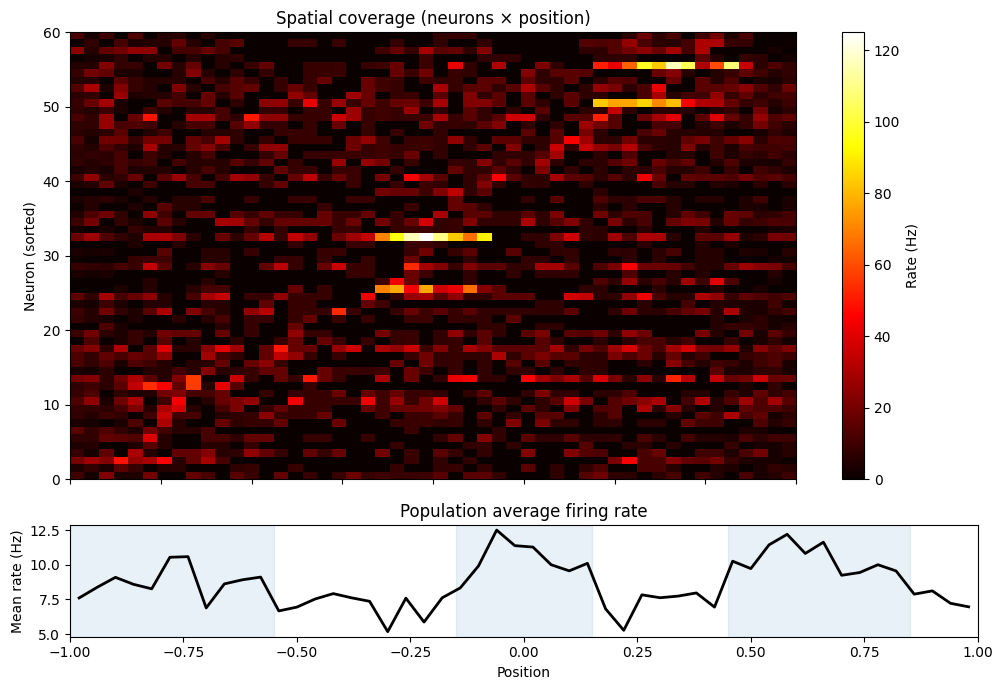

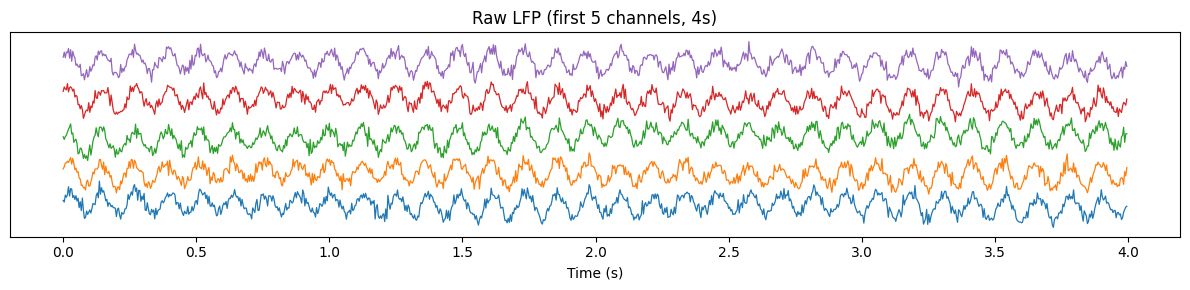

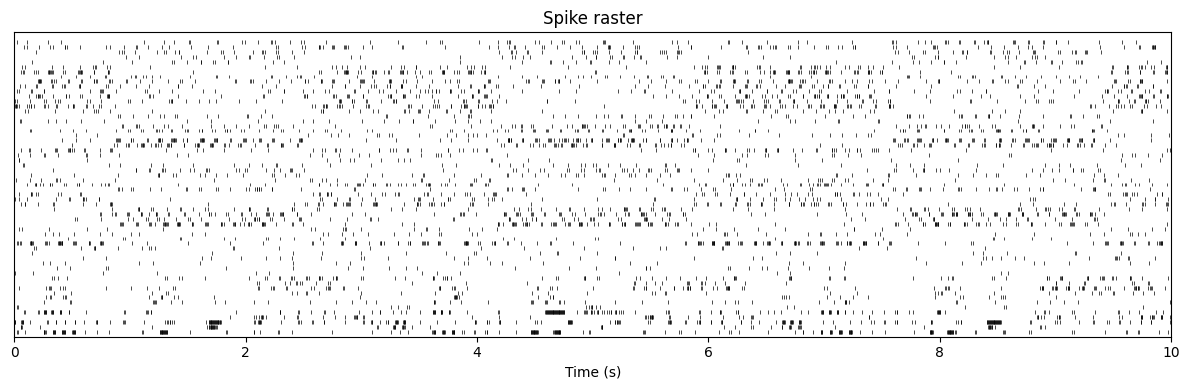

Example place cell index: 0


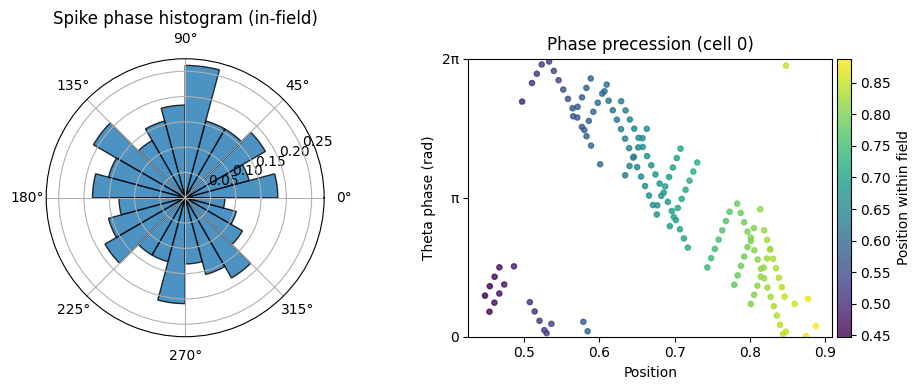

Circular mean phase (in-field): 2.17 rad, n_spikes=146
Example head-direction cell index: 18


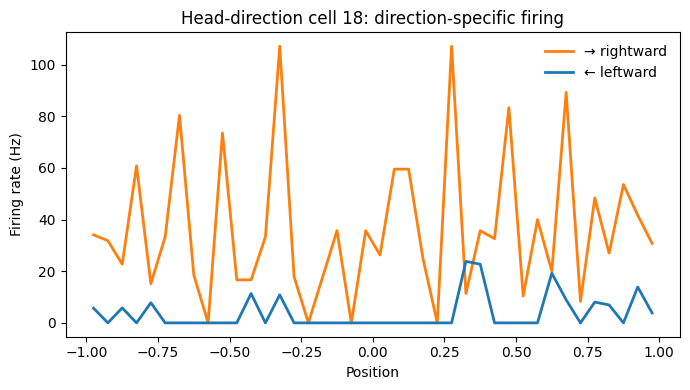

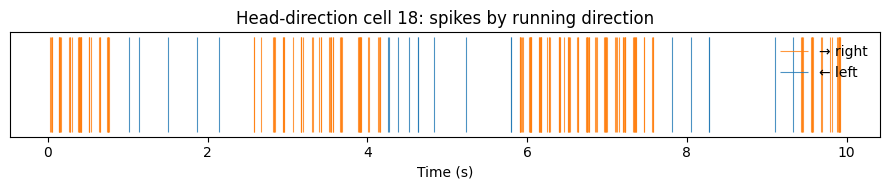

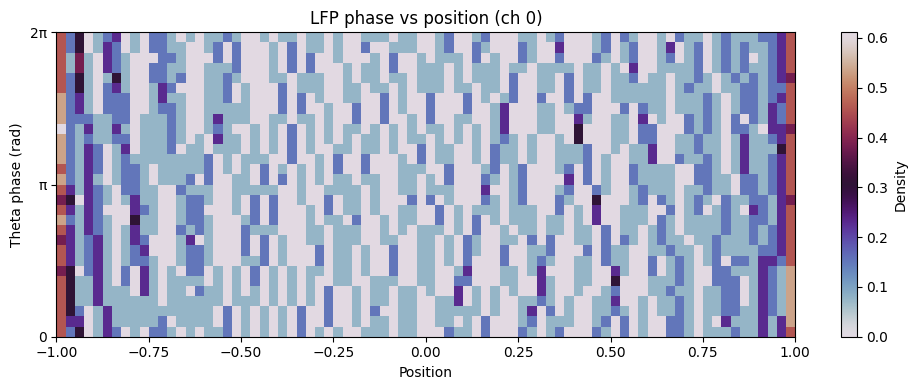

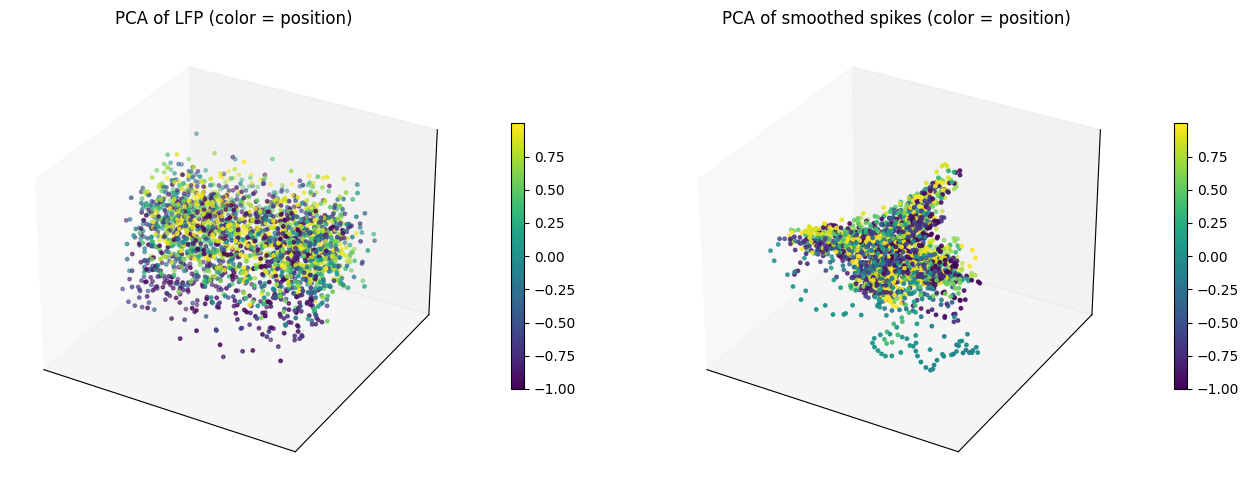

In [12]:
# ============================================================
# 6) VISUALIZATIONS  (sanity-checked, all aligned)
# ============================================================
# -----------------------------
# Population coverage heatmap + mean firing rate
# -----------------------------
mean_rate = coverage.mean(axis=0)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                       gridspec_kw={'height_ratios':[4,1]})

im = ax[0].imshow(coverage[order], aspect='auto', origin='lower',
                  extent=[-1,1,0,n_cells_total],
                  interpolation='nearest', cmap='hot')
ax[0].set_title("Spatial coverage (neurons × position)")
ax[0].set_ylabel("Neuron (sorted)")
plt.colorbar(im, ax=ax[0], label="Rate (Hz)")

ax[1].plot(cent, mean_rate, color='black', lw=2)
ax[1].set_xlabel("Position")
ax[1].set_ylabel("Mean rate (Hz)")
ax[1].set_title("Population average firing rate")

if ALLOW_SEGMENTS is not None:
    for seg in ALLOW_SEGMENTS:
        ax[1].axvspan(seg[0], seg[1], color='tab:blue', alpha=0.1)
plt.tight_layout(); plt.show()

# -----------------------------
# LFP strip plot (first few channels)
# -----------------------------
sec = 4
t_idx = slice(0, sec*fs)
n_show = min(5, n_lfp)
fig, ax = plt.subplots(figsize=(12,3))
offset = 3.0
for k in range(n_show):
    ax.plot(t[t_idx], lfp_raw[t_idx, k] + k*offset, lw=0.9)
ax.set_title(f"Raw LFP (first {n_show} channels, {sec}s)")
ax.set_xlabel("Time (s)")
ax.set_yticks([])
plt.tight_layout(); plt.show()

# -----------------------------
# Spike raster
# -----------------------------
fig, ax = plt.subplots(figsize=(12,4))
spike_times = [np.where(spikes[i])[0]/fs for i in range(n_cells_total)]
ax.eventplot(spike_times, colors='k', lineoffsets=np.arange(n_cells_total),
             linelengths=0.8, lw=0.5)
ax.set_xlim(0, T_sec); ax.set_ylim(-1, n_cells_total+1)
ax.set_title("Spike raster")
ax.set_xlabel("Time (s)"); ax.set_yticks([])
plt.tight_layout(); plt.show()

# -----------------------------
# Example place cell: phase precession
# -----------------------------
place_idx = np.where(labels == "place")[0]
if place_idx.size:
    i_example = int(place_idx[0])
    print(f"Example place cell index: {i_example}")

    n_bins = 50
    edges = np.linspace(-1, 1, n_bins + 1)
    pos_bins = np.digitize(x, edges) - 1
    spike_counts = np.bincount(pos_bins[spikes[i_example]], minlength=n_bins)
    occ_counts   = np.bincount(pos_bins, minlength=n_bins)
    rate_per_pos = spike_counts / (occ_counts + 1e-9)
    mu_est = edges[np.argmax(rate_per_pos)]
    sig_est = 0.15
    field_mask = (x > mu_est - 0.25) & (x < mu_est + 0.25)
    idx_sp = np.where(spikes[i_example] & field_mask)[0]
    if len(idx_sp) > 0:
        pos_in_field   = x[idx_sp]
        phase_in_field = phi_theta[idx_sp] % (2 * np.pi)

        fig = plt.figure(figsize=(10, 4))
        # Polar histogram
        ax1 = fig.add_subplot(1, 2, 1, projection='polar')
        n_bins_phase = 24
        bin_edges = np.linspace(0, 2*np.pi, n_bins_phase + 1)
        counts, _ = np.histogram(phase_in_field, bins=bin_edges, density=True)
        theta = 0.5 * (bin_edges[:-1] + bin_edges[1:])
        ax1.bar(theta, counts, width=(2*np.pi/n_bins_phase),
                align='center', alpha=0.8, edgecolor='k')
        ax1.set_title("Spike phase histogram (in-field)")

        # Phase precession scatter
        ax2 = fig.add_subplot(1, 2, 2)
        sc = ax2.scatter(pos_in_field, phase_in_field, s=14, alpha=0.8,
                         c=pos_in_field, cmap='viridis')
        ax2.set_ylim(0, 2*np.pi)
        ax2.set_yticks([0, np.pi, 2*np.pi])
        ax2.set_yticklabels(["0", "π", "2π"])
        ax2.set_xlabel("Position"); ax2.set_ylabel("Theta phase (rad)")
        ax2.set_title(f"Phase precession (cell {i_example})")
        plt.colorbar(sc, ax=ax2, label="Position within field", pad=0.01)
        plt.tight_layout(); plt.show()
        mean_phase = circmean(phase_in_field, high=2*np.pi, low=0)
        print(f"Circular mean phase (in-field): {mean_phase:.2f} rad, n_spikes={len(idx_sp)}")

# -----------------------------
# Example head-direction cell visualization
# -----------------------------
hd_idx = np.where(labels == "hd")[0]
if hd_idx.size:
    i_hd = int(hd_idx[0])
    print(f"Example head-direction cell index: {i_hd}")

    dir_signal = np.sign(v_animal)
    dir_signal[dir_signal == 0] = 1
    n_bins_dir = 40
    edges_dir  = np.linspace(-1, 1, n_bins_dir + 1)
    centers_dir = 0.5 * (edges_dir[:-1] + edges_dir[1:])
    rates_right = np.zeros(n_bins_dir)
    rates_left  = np.zeros(n_bins_dir)
    occ_right   = np.zeros(n_bins_dir)
    occ_left    = np.zeros(n_bins_dir)
    pos_bins = np.clip(np.digitize(x, edges_dir) - 1, 0, n_bins_dir - 1)

    
    for j in range(N):
        if dir_signal[j] > 0: occ_right[pos_bins[j]] += 1
        else:                 occ_left[pos_bins[j]]  += 1
    spike_idx = np.where(spikes[i_hd])[0]
    for j in spike_idx:
        if dir_signal[j] > 0: rates_right[pos_bins[j]] += 1
        else:                 rates_left[pos_bins[j]]  += 1
    rates_right = rates_right / (occ_right / fs + 1e-9)
    rates_left  = rates_left  / (occ_left  / fs + 1e-9)

    # rate vs. position
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(centers_dir, rates_right, color="tab:orange", lw=2, label="→ rightward")
    ax.plot(centers_dir, rates_left,  color="tab:blue", lw=2, label="← leftward")
    ax.set_xlabel("Position"); ax.set_ylabel("Firing rate (Hz)")
    ax.set_title(f"Head-direction cell {i_hd}: direction-specific firing")
    ax.legend(frameon=False); plt.tight_layout(); plt.show()

    # raster by direction
    fig, ax = plt.subplots(figsize=(9, 2))
    right_times = np.where(spikes[i_hd] & (dir_signal > 0))[0] / fs
    left_times  = np.where(spikes[i_hd] & (dir_signal < 0))[0] / fs
    ax.vlines(right_times, 0, 1, color="tab:orange", alpha=0.8, lw=0.8, label="→ right")
    ax.vlines(left_times,  0, 1, color="tab:blue",   alpha=0.8, lw=0.8, label="← left")
    ax.set_xlabel("Time (s)"); ax.set_yticks([])
    ax.set_title(f"Head-direction cell {i_hd}: spikes by running direction")
    ax.legend(frameon=False); plt.tight_layout(); plt.show()

# -----------------------------
# LFP phase vs position (sanity alignment)
# -----------------------------
ch = 0  # example channel
plt.figure(figsize=(10,4))
plt.hist2d(x, lfp_phase_inst[:, ch], bins=(80, 30),
           range=[[-1,1],[0,2*np.pi]], cmap='twilight', density=True)
plt.xlabel("Position"); plt.ylabel("Theta phase (rad)")
plt.title(f"LFP phase vs position (ch {ch})")
plt.colorbar(label='Density')
plt.yticks([0, np.pi, 2*np.pi], ['0', 'π', '2π'])
plt.tight_layout(); plt.show()

# -----------------------------
# PCA snapshots (color by position)
# -----------------------------
A_spike = gaussian_filter1d(spikes.astype(float), sigma=2, axis=1).T
B_lfp   = lfp_raw.astype(np.float32)
Z_lfp  = PCA(n_components=3).fit_transform(B_lfp)
Z_rate = PCA(n_components=3).fit_transform(A_spike)
color  = x

fig = plt.figure(figsize=(14,5))
ax = fig.add_subplot(1,2,1, projection='3d')
p = ax.scatter(Z_lfp[:,0], Z_lfp[:,1], Z_lfp[:,2], c=color, s=6, cmap='viridis')
ax.set_title("PCA of LFP (color = position)")
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.02, pad=0.08)

ax = fig.add_subplot(1,2,2, projection='3d')
p = ax.scatter(Z_rate[:,0], Z_rate[:,1], Z_rate[:,2], c=color, s=6, cmap='viridis')
ax.set_title("PCA of smoothed spikes (color = position)")
ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.colorbar(p, ax=ax, fraction=0.02, pad=0.08)
plt.tight_layout(); plt.show()


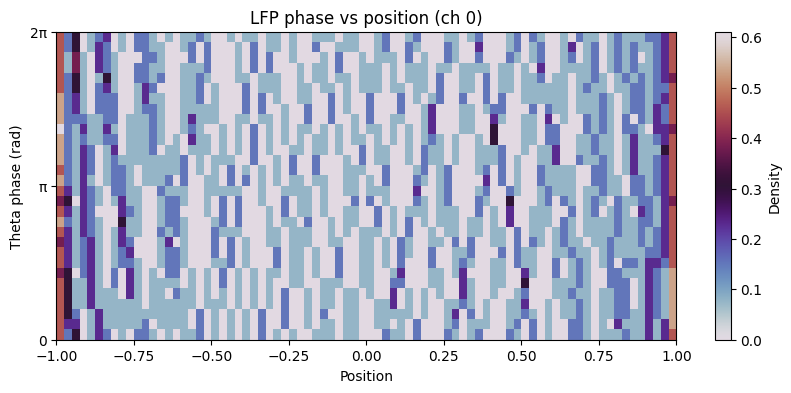

In [13]:
plt.figure(figsize=(10,4))
plt.hist2d(x, lfp_phase_inst[:, ch], bins=(80, 30),
           range=[[-1,1],[0,2*np.pi]], cmap='twilight', density=True)
plt.xlabel("Position"); plt.ylabel("Theta phase (rad)")
plt.title(f"LFP phase vs position (ch {ch})")
plt.colorbar(label='Density')
plt.yticks([0, np.pi, 2*np.pi], ['0', 'π', '2π'])
plt.show()


In [19]:

from scipy.stats import binned_statistic

C:\Users\zckti\AppData\Local\Temp\ipykernel_32012\2906952526.py:99: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


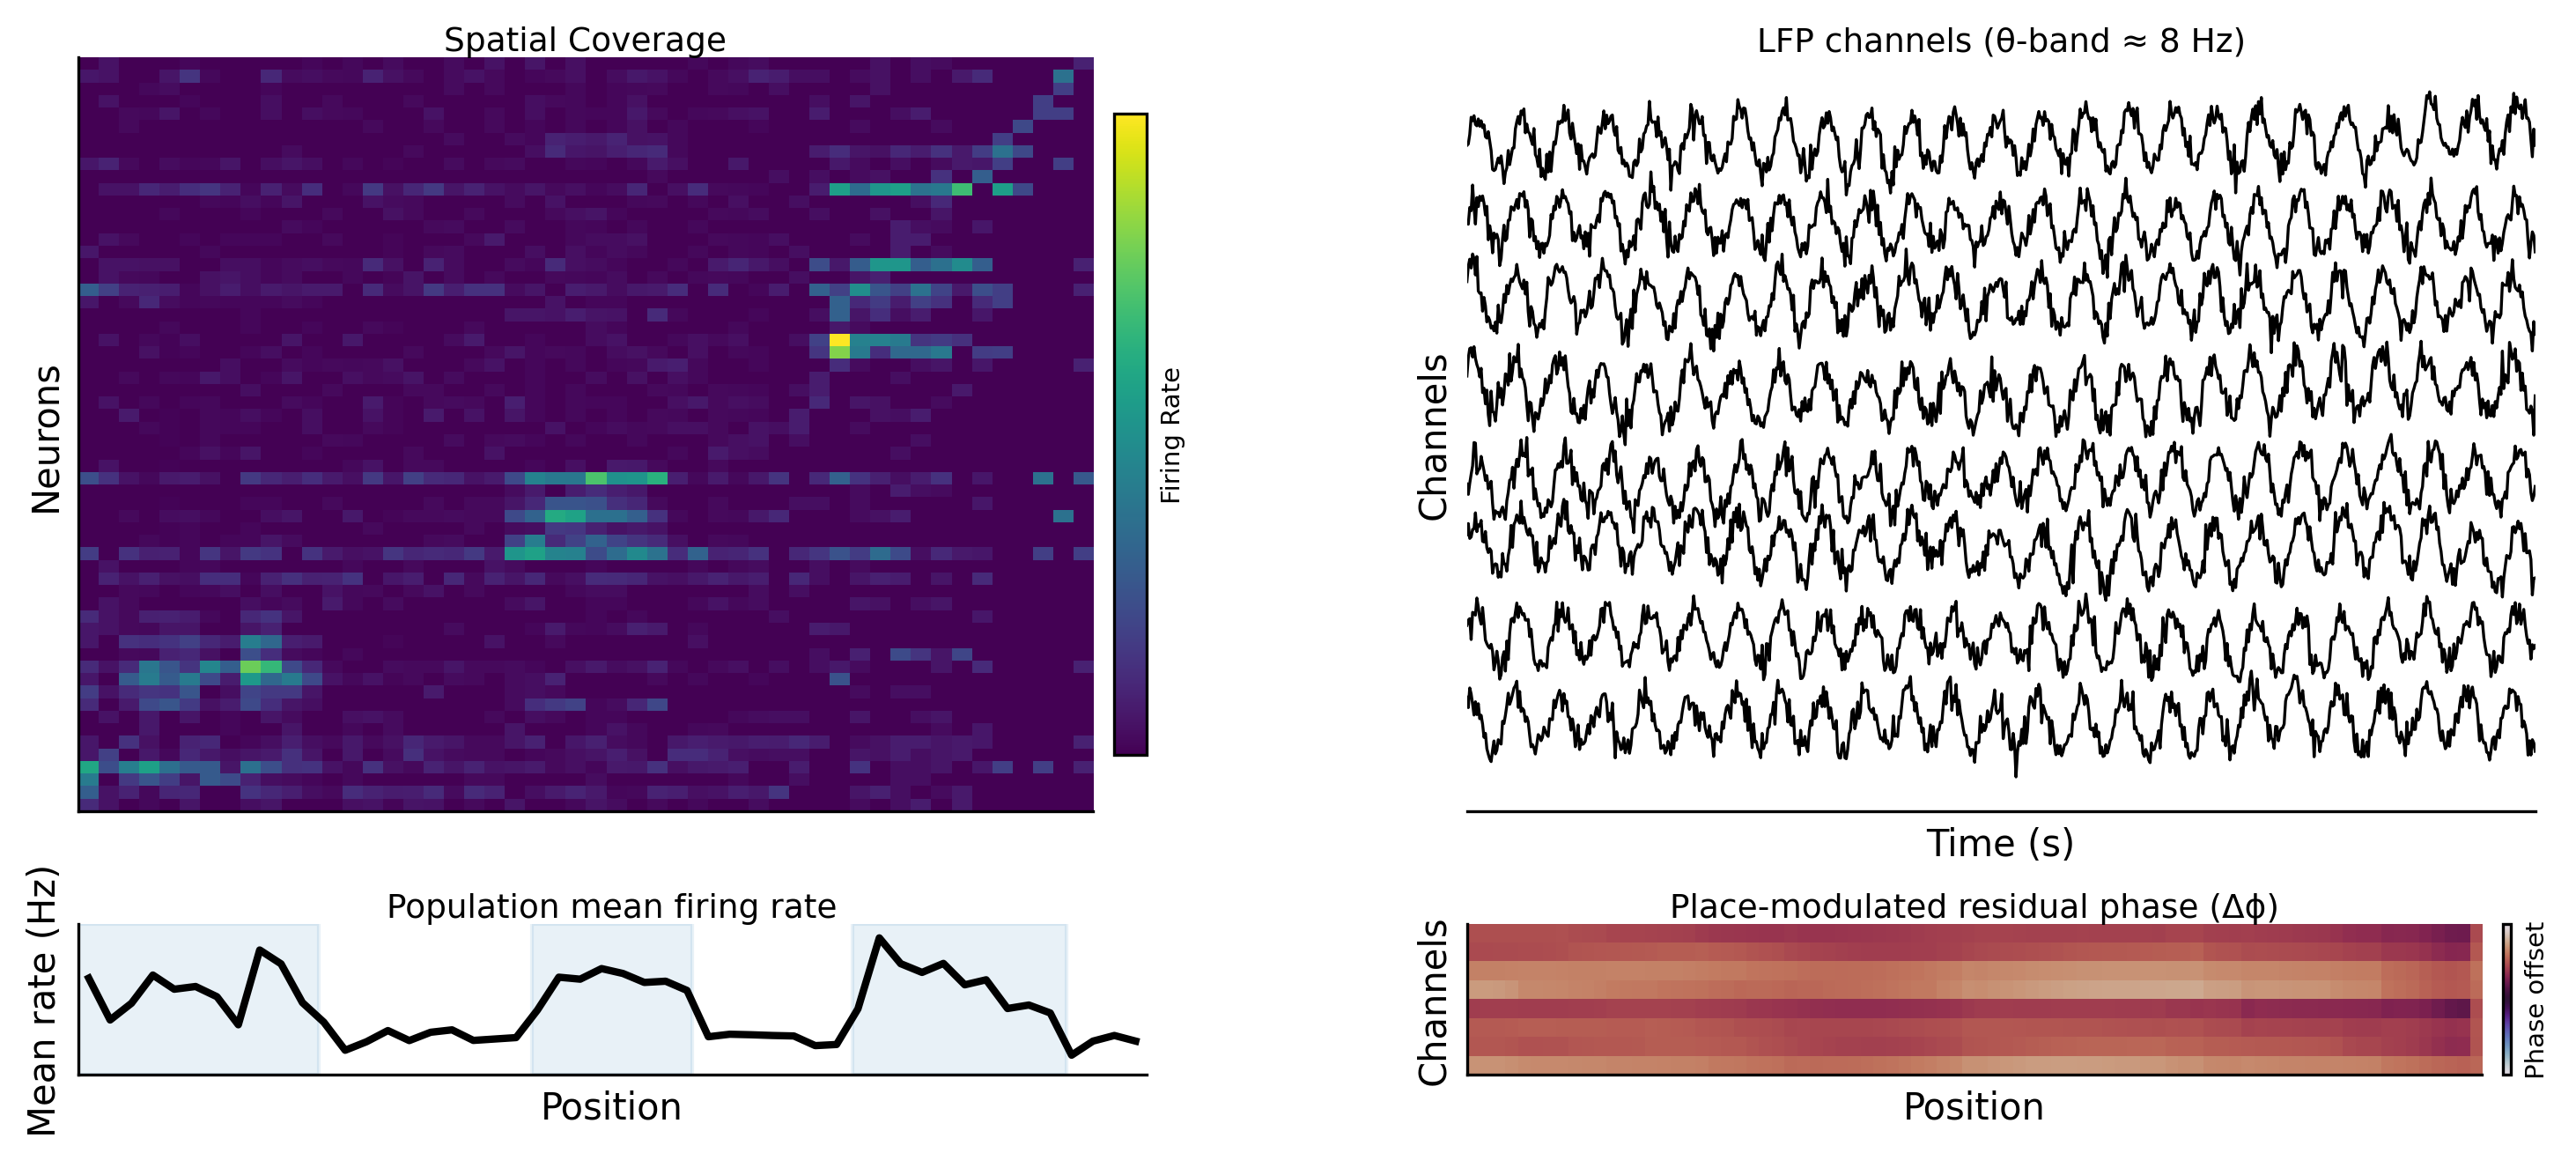

In [33]:
# ----------------------------------------------------------
# (1) Compute residual phase-offset matrix (LFP)
# ----------------------------------------------------------
n_bins_pos = 80
phase_matrix = np.zeros((n_lfp, n_bins_pos))
edges = np.linspace(-1, 1, n_bins_pos + 1)
centers = 0.5 * (edges[:-1] + edges[1:])

for ch in range(n_lfp):
    phase_diff = (lfp_phase_inst[:, ch] - (phi_theta % (2 * np.pi))) % (2 * np.pi)
    stat, _, _ = binned_statistic(x, np.exp(1j * phase_diff),
                                  bins=edges, statistic="mean")
    phase_matrix[ch] = np.angle(stat)
phase_matrix = (phase_matrix + 2 * np.pi) % (2 * np.pi)

# ----------------------------------------------------------
# (2) Compute mean firing rate along position
# ----------------------------------------------------------
mean_rate = coverage.mean(axis=0)

# ----------------------------------------------------------
# (3) Make 2×2 figure
# ----------------------------------------------------------
fig = plt.figure(figsize=(12, 5), dpi=300)
gs = fig.add_gridspec(2, 2, height_ratios=[3.0, 0.6], hspace=0.25, wspace=0.3)

# ---------- (a) Raw LFP traces ----------
ax1 = fig.add_subplot(gs[0, 1])
sec = 3
t_idx = slice(0, sec * fs)
offset = 3.0
for k in range(n_lfp):
    ax1.plot(t[t_idx], lfp_raw[t_idx, k] + k * offset, lw=0.8, color="black")

# Axes styling
ax1.set_xlim(t[t_idx][0], t[t_idx][-1])
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Channels")

# keep x-axis line but no ticks or tick labels
ax1.tick_params(axis="x", which="both", bottom=False, labelbottom=False)

# hide y-axis and ticks, keep only label
ax1.tick_params(axis="y", which="both", left=False, labelleft=False)

# keep bottom spine (x-axis line), hide top/right
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_visible(False)
ax1.set_title("LFP channels (θ-band ≈ 8 Hz)", fontsize=9, pad=2)

# ---------- (b) Spatial coverage heatmap ----------
ax2 = fig.add_subplot(gs[0, 0])
im_cov = ax2.imshow(coverage[order], aspect='auto', origin='lower',
                    extent=[-1, 1, 0, n_cells_total],
                    interpolation='nearest', cmap='viridis')
ax2.set_title("Spatial Coverage", fontsize=9, pad=2)
ax2.set_xticks([]); ax2.set_xlabel("")
ax2.set_yticks([]); ax2.set_ylabel("Neurons")
for spine in ["top", "right"]:
    ax2.spines[spine].set_visible(False)

cbar_cov = plt.colorbar(im_cov, ax=ax2, fraction=0.03, pad=0.02)
cbar_cov.set_label("Firing Rate", fontsize=7)
cbar_cov.set_ticks([])     # 🚫 turn off colorbar ticks

# ---------- (c) Residual LFP phase map ----------
ax3 = fig.add_subplot(gs[1, 1])
im_phase = ax3.imshow(phase_matrix, aspect="auto", origin="lower",
                      extent=[-1, 1, 0, n_lfp],
                      cmap="twilight", vmin=0, vmax=2 * np.pi)
ax3.set_xticks([]); ax3.set_yticks([])
ax3.set_ylabel("Channels"); ax3.set_xlabel("")
ax3.set_title("Place-modulated residual phase (Δϕ)", fontsize=9, pad=2)
for spine in ["top", "right"]:
    ax3.spines[spine].set_visible(False)
ax3.set_xlabel('Position')
cbar_phase = plt.colorbar(im_phase, ax=ax3, fraction=0.03, pad=0.02)
cbar_phase.set_label("Phase offset", fontsize=7)
cbar_phase.set_ticks([])   # 🚫 turn off colorbar ticks


# ---------- (d) Mean population firing rate ----------
ax4 = fig.add_subplot(gs[1, 0])
ax4.plot(cent, mean_rate, color='black', lw=2)
ax4.set_xlabel("Position")
ax4.set_ylabel("Mean rate (Hz)")
ax4.set_title("Population mean firing rate", fontsize=9, pad=2)
ax4.set_xlim(-1, 1)
ax4.set_ylim(0, mean_rate.max() * 1.1)
ax4.set_xticks([])
ax4.set_yticks([])
if ALLOW_SEGMENTS is not None:
    for seg in ALLOW_SEGMENTS:
        ax4.axvspan(seg[0], seg[1], color='tab:blue', alpha=0.1)
for spine in ["top", "right"]:
    ax4.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()


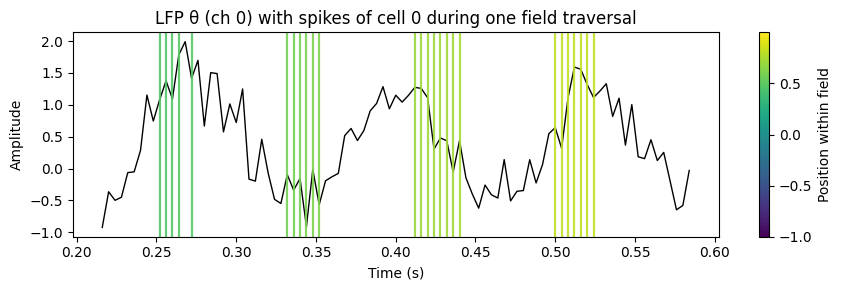

In [14]:
# ============================================================
# LFP theta + spike timing for one traversal of the place field
# ============================================================

ch_show = 0
fs = dataset["fs"] if "dataset" in locals() else fs

# --- 1. Estimate the field center as before ---
n_bins = 50
edges = np.linspace(-1, 1, n_bins + 1)
pos_bins = np.digitize(x, edges) - 1
spike_counts = np.bincount(pos_bins[spikes[i_example]], minlength=n_bins)
occ_counts   = np.bincount(pos_bins, minlength=n_bins)
rate_per_pos = spike_counts / (occ_counts + 1e-9)
mu_est = edges[np.argmax(rate_per_pos)]
field_halfwidth = 0.25
field_mask = (x > mu_est - field_halfwidth) & (x < mu_est + field_halfwidth)

# --- 2. Identify continuous field-crossing segments ---
cross_idx = np.where(field_mask)[0]
# Split into separate continuous segments
segments = np.split(cross_idx, np.where(np.diff(cross_idx) > 1)[0] + 1)

# Pick the first meaningful traversal (long enough)
segments = [seg for seg in segments if len(seg) > int(0.2 * fs)]
if not segments:
    print("No valid in-field traversal found.")
else:
    seg = segments[0]  # first traversal
    seg_start, seg_stop = seg[0], seg[-1]
    t_seg = t[seg_start:seg_stop]
    lfp_seg = lfp_raw[seg_start:seg_stop, ch_show]

    # --- 3. Spikes from this neuron during that traversal ---
    spike_times = np.where(spikes[i_example])[0]
    spike_times_pass = spike_times[
        (spike_times >= seg_start) & (spike_times <= seg_stop)
    ] / fs
    pos_interp = np.interp(spike_times_pass, t, x)
    colors = plt.cm.viridis((pos_interp - np.min(x)) / (np.max(x) - np.min(x)))

    # --- 4. Plot ---
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(t_seg, lfp_seg, color="black", lw=1.0)
    for tt, c in zip(spike_times_pass, colors):
        ax.axvline(tt, color=c, lw=1.6, alpha=0.9)
    ax.set_title(
        f"LFP θ (ch {ch_show}) with spikes of cell {i_example} "
        f"during one field traversal"
    )
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Amplitude")
    sm = plt.cm.ScalarMappable(cmap="viridis")
    sm.set_array(x)
    plt.colorbar(sm, ax=ax, label="Position within field")
    plt.tight_layout()
    plt.show()
